# **Classification Project: German Credit Risk Prediction**

Welcome to the classification project.

In this project, you will build machine learning models to predict whether a credit applicant is a **good** or **bad** credit risk.

---
## **Objective**
---
The objective of this project is to:
- Perform exploratory data analysis (EDA)
- Apply proper preprocessing using Pipelines
- Build and tune classification models
- Compare models and justify a final recommendation


---
## **Dataset Description**
---
We use the **German Credit dataset (credit-g, OpenML id 31)**.

Each row represents a loan applicant described by a mixture of numerical and categorical features.

Target variable:
- `good` = 0
- `bad` = 1

You will load the dataset using `fetch_openml`.


## **Importing the necessary libraries**

In [1]:

# Import necessary libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer, make_column_selector as selector
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

np.random.seed(42)


## **Loading the Dataset**

In [2]:

# Load dataset using fetch_openml
Xy = fetch_openml(data_id=31, as_frame=True)
X = Xy.data
y_raw = Xy.target

y_raw
# Map target labels to integers (good=0, bad=1)
y= y_raw.map({'good': 0, 'bad': 1})
y.unique()



[0, 1]
Categories (2, int64): [1, 0]

---
## **Data Overview**
---
- Number of observations
- Number of features
- Class distribution
- Check for missing values


In [3]:
# Inspect dataset shape
print(X.shape)
# Display first few rows
X.head()
# Show class distribution
X.describe()

(1000, 20)


,duration,credit_amount,installment_commitment,residence_since,age,existing_credits,num_dependents
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,20.903000,3271.258000,2.973000,2.845000,35.546000,1.407000,1.155000
std,12.058814,2822.736876,1.118715,1.103718,11.375469,0.577654,0.362086
min,4.000000,250.000000,1.000000,1.000000,19.000000,1.000000,1.000000
25%,12.000000,1365.500000,2.000000,2.000000,27.000000,1.000000,1.000000
50%,18.000000,2319.500000,3.000000,3.000000,33.000000,1.000000,1.000000
75%,24.000000,3972.250000,4.000000,4.000000,42.000000,2.000000,1.000000
max,72.000000,18424.000000,4.000000,4.000000,75.000000,4.000000,2.000000


In [4]:

# Check missing values
X.info()
print(X.isna().sum().sum())
print(y.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   checking_status         1000 non-null   category
 1   duration                1000 non-null   int64   
 2   credit_history          1000 non-null   category
 3   purpose                 1000 non-null   category
 4   credit_amount           1000 non-null   int64   
 5   savings_status          1000 non-null   category
 6   employment              1000 non-null   category
 7   installment_commitment  1000 non-null   int64   
 8   personal_status         1000 non-null   category
 9   other_parties           1000 non-null   category
 10  residence_since         1000 non-null   int64   
 11  property_magnitude      1000 non-null   category
 12  age                     1000 non-null   int64   
 13  other_payment_plans     1000 non-null   category
 14  housing                 1000 non-nul

---
## **Exploratory Data Analysis (EDA)**
---
EDA is crucial before building models. Investigate distributions and relationships.

**Questions to guide your analysis:**
1. Is the dataset imbalanced?
2. What do the distributions of key numeric features look like?
3. Are there noticeable differences between good and bad applicants?
4. What preprocessing steps seem necessary based on your observations?


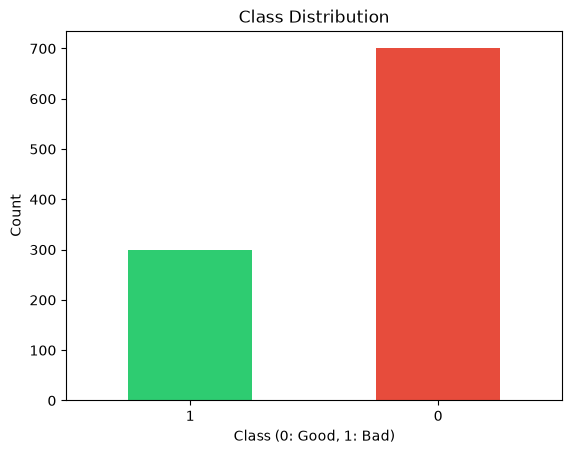

In [5]:


# Plot class distribution
# Define the colors in the order they appear in the distribution (0 then 1)
colors = ['#2ecc71','#e74c3c']
y.value_counts().sort_index().plot(kind='bar', color=colors)

plt.title('Class Distribution')
plt.xlabel('Class (0: Good, 1: Bad)')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()


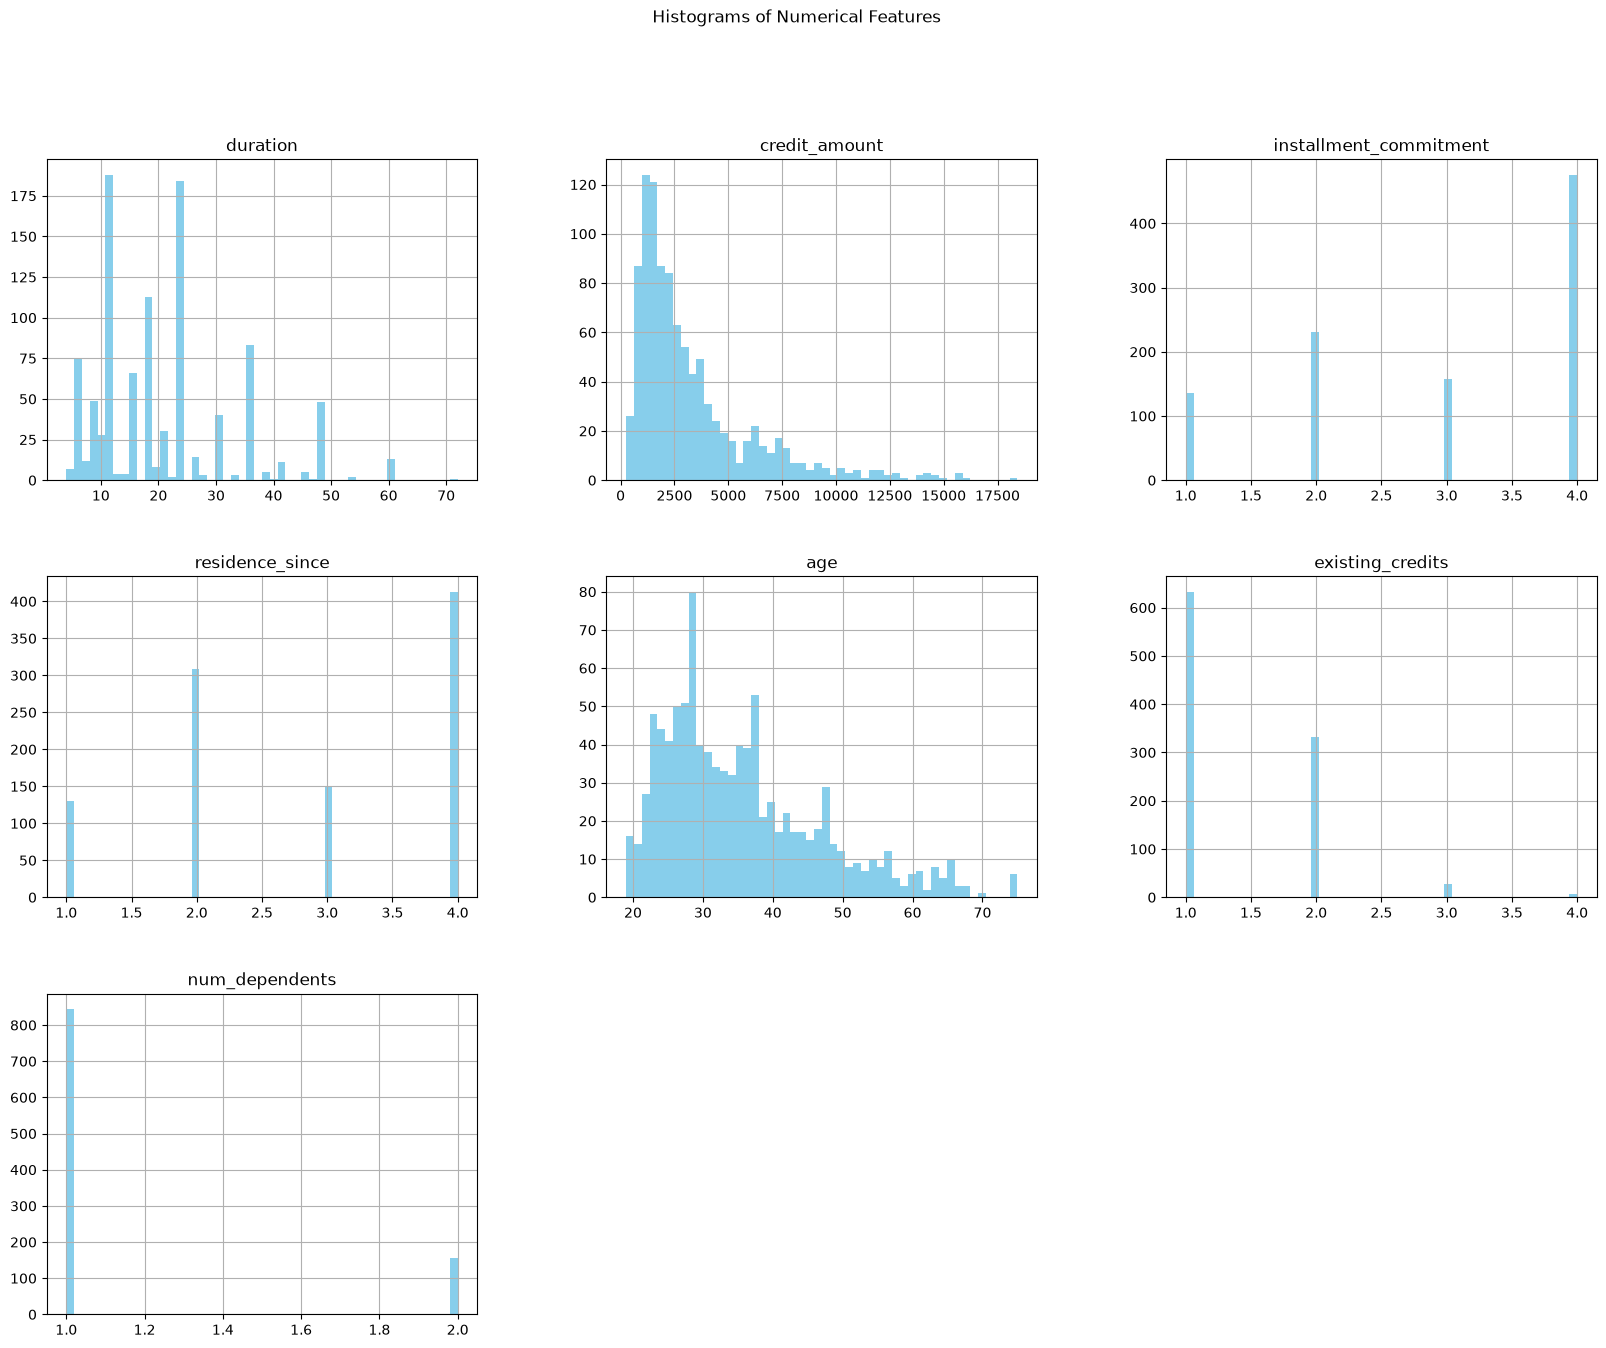

In [6]:

# Plot histograms for selected numeric features
X.hist(bins=50, figsize=(20,15),color="skyblue")
plt.suptitle('Histograms of Numerical Features') # Adjust suptitle position
plt.show()


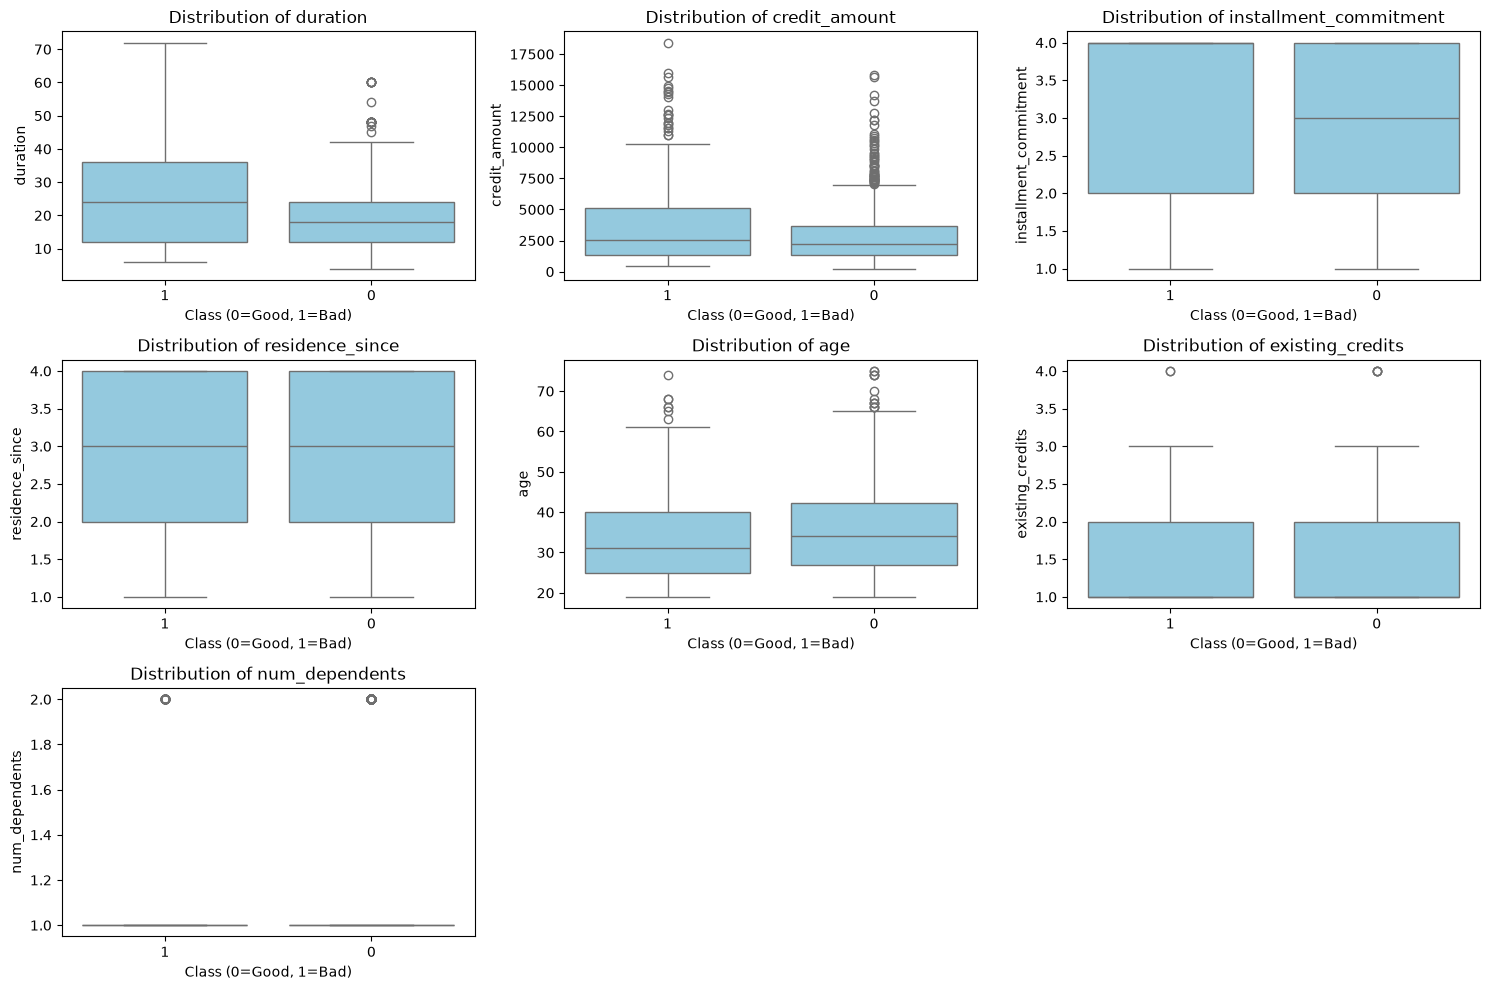

In [7]:
# Boxplots of numeric features by class
import seaborn as sns

# 1. We identify numerical columns of X
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns

plt.figure(figsize=(15, 10))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(x=y, y=X[col],color="skyblue")
    plt.title(f'Distribution of {col}')
    plt.xlabel('Class (0=Good, 1=Bad)')

plt.tight_layout()
plt.show()


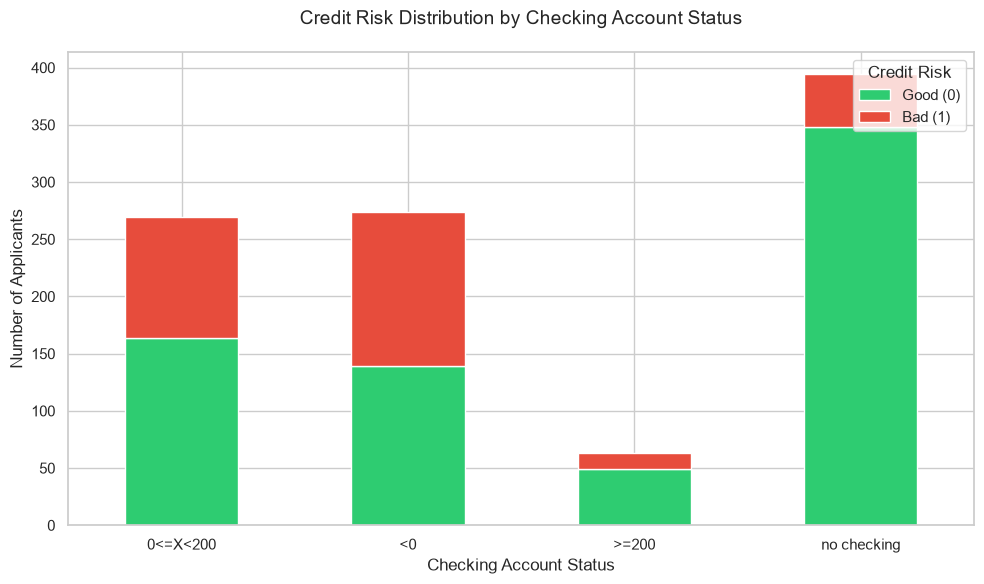

In [8]:
# Explore one categorical feature vs target
# Example: 'checking_status' vs target
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

ct = pd.crosstab(X['checking_status'], y)[[0, 1]]

ax = ct.plot(kind='bar',
             stacked=True,
             figsize=(10, 6),
             color=['#2ecc71', '#e74c3c'],  # Verde para 0, Rojo para 1
             edgecolor='white')

plt.title('Credit Risk Distribution by Checking Account Status', fontsize=14, pad=20)
plt.xlabel('Checking Account Status', fontsize=12)
plt.ylabel('Number of Applicants', fontsize=12)

plt.legend(title='Credit Risk', labels=['Good (0)', 'Bad (1)'], loc='upper right')

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

---
## **Data Preprocessing**
---
- Split into train and test sets (use stratification)
- Keep the test set untouched until final evaluation
- Use Pipeline + ColumnTransformer
- Scale numerical features
- One-hot encode categorical features


In [9]:
# Train/test split with stratification
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,     # Reserves 20% of the data for the test set
    random_state=42,    # Ensures reproducible results
    stratify=y          # Maintains the 70/30 class balance in both sets
)

# Optional: Print the shapes to verify it worked
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

# Optional: Verify the stratification worked (both should be around 0.30)
print(f"Proportion of Bad credit in Train: {y_train.value_counts(normalize=True)[1]:.2f}")
print(f"Proportion of Bad credit in Test: {y_test.value_counts(normalize=True)[1]:.2f}")

X_train shape: (800, 20)
X_test shape: (200, 20)
Proportion of Bad credit in Train: 0.30
Proportion of Bad credit in Test: 0.30


In [10]:
# Define numeric and categorical pipelines


# 1. Automatically identify numeric and categorical columns from your dataframe 'X'
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

# Define numeric pipeline
# The numeric pipeline only needs one step: scaling the data (z)
numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

# Define categorical pipeline
# The categorical pipeline uses One-Hot Encoding
# handle_unknown='ignore' ensures that if a rare category appears in the test set
# that wasn't in the training set, it won't crash the code.
categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

In [11]:
# Combine using ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        # ('name', transformer_object, list_of_columns)
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

---
## **Conceptual Question: Perceptron (No Implementation)**
---
Answer the following in markdown:

1. **What assumptions does the Perceptron make?** That the data is bounded and linearly separable by a hyperplane
2. **When is convergence guaranteed?** Convergence is guaranteed if and only if the dataset is perfectly linearly separable and the data is bounded.
3. **Is it likely appropriate for this dataset? Why or why not?** The perceptron is going to be highly unlikely appropiate for this data set. Althought the data is bounded, two identic inputs can have different outputs. Furthermore real-world data is almost never linearly separable, especially in this case, knowing that human behavior is complex.


---
## **Model Building: Linear Models**
---
You will build and tune:
- Logistic Regression
- Linear SVM

Use cross-validation on the training set to tune `C`.


In [12]:
# Build Logistic Regression pipeline
logreg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor), # The ColumnTransformer we built earlier
    ('classifier', LogisticRegression(random_state=42, max_iter=1000)) # The model
])

In [13]:
# Tune C using GridSearchCV


# 1. Define the grid of C values you want to test
# IMPORTANT: Because LogisticRegression is inside a pipeline and we named the step 'classifier',
# we must use the syntax 'classifier__C' (with TWO underscores) to tell the grid exactly what to change.
param_grid = {
    'classifier__C': [0.001, 0.01, 0.1, 1, 10, 100]
}

# 2. Define the Cross-Validation strategy
# We use StratifiedKFold to maintain the 70/30 Good/Bad ratio in every mini-fold
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 3. Set up GridSearchCV
# We pass the entire logreg_pipeline into the search
grid_search = GridSearchCV(
    estimator=logreg_pipeline,
    param_grid=param_grid,
    cv=cv_strategy,
    scoring='f1', # Since the ratio is 70/30 using accuracy is not fair
)

# 4. Start the search (This does the scaling, encoding, and training all at once!)
grid_search.fit(X_train, y_train)

# 5. Print the winning results
print(f"Best C value found: {grid_search.best_params_['classifier__C']}")
print(f"Best cross-validation F1 score: {grid_search.best_score_:.4f}")

Best C value found: 10
Best cross-validation F1 score: 0.5035


---
## **Model Building: Logistic Regression**
---



In [14]:
# Evaluate on test set
y_pred = grid_search.predict(X_test)

Logistic Regression Performance (Threshold: 50% | Target: Bad):

Accuracy:  0.78
Precision: 0.64
Recall:    0.58
F1-score:  0.61



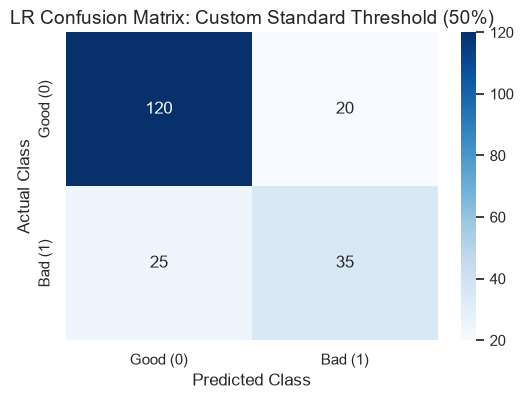

In [15]:
# 1. Import the necessary grading tools
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Evaluate on test set
# The model takes the final exam using the 200 unseen rows (default 50% threshold)
y_pred = grid_search.predict(X_test)

# 3. Calculate the four core metrics
# Note: precision, recall, and f1 automatically focus on class 1 ('Bad') by default
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# 4. Print the clean, simple report
print(f"Logistic Regression Performance (Threshold: 50% | Target: Bad):\n")
print(f"Accuracy:  {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall:    {recall:.2f}")
print(f"F1-score:  {f1:.2f}\n")

# 5. Plot the Confusion Matrix to visualize the exact mistakes
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Good (0)', 'Bad (1)'],
            yticklabels=['Good (0)', 'Bad (1)'])
plt.title(f'LR Confusion Matrix: Custom Standard Threshold (50%)', fontsize=14)
plt.ylabel('Actual Class', fontsize=12)
plt.xlabel('Predicted Class', fontsize=12)
plt.show()

In [16]:
# Choosing the LR threshold with cross-validation (training set only)
from sklearn.model_selection import cross_val_predict

# 1. Get out-of-fold probabilities for the training set
# Each training sample is predicted by a model that did NOT see it during training,
# so we can tune the threshold without ever touching the test set (no data leakage).
best_lr = grid_search.best_estimator_
oof_prob_bad = cross_val_predict(best_lr, X_train, y_train, cv=cv_strategy, method='predict_proba')[:, 1]

# 2. Business rule: get a better recall without drastically decreasing accuracy
# -> we accept losing at most 3 points of accuracy compared to the default 50% threshold
max_accuracy_drop = 0.03
baseline_accuracy = accuracy_score(y_train, (oof_prob_bad >= 0.5).astype(int))

# 3. Evaluate every candidate threshold on the out-of-fold predictions
candidate_thresholds = np.round(np.arange(0.20, 0.51, 0.05), 2)
threshold_results = []
for t in candidate_thresholds:
    y_oof = (oof_prob_bad >= t).astype(int)
    threshold_results.append({
        'Threshold': t,
        'Accuracy':  accuracy_score(y_train, y_oof),
        'Recall':    recall_score(y_train, y_oof),
        'F1-score':  f1_score(y_train, y_oof)
    })
threshold_table_lr = pd.DataFrame(threshold_results).round(3)

# 4. Keep the threshold with the highest recall among the ones that respect the rule
valid_lr = threshold_table_lr[threshold_table_lr['Accuracy'] >= baseline_accuracy - max_accuracy_drop]
best_threshold_lr = float(valid_lr.sort_values('Recall', ascending=False).iloc[0]['Threshold'])

print(f"Out-of-fold accuracy with the default 50% threshold: {baseline_accuracy:.3f}")
print(f"Minimum accepted accuracy: {baseline_accuracy - max_accuracy_drop:.3f}")
print(f"Threshold selected with cross-validation: {best_threshold_lr}")
print()
display(threshold_table_lr)


Out-of-fold accuracy with the default 50% threshold: 0.740
Minimum accepted accuracy: 0.710
Threshold selected with cross-validation: 0.35



,Threshold,Accuracy,Recall,F1-score
0,0.20,0.650,0.788,0.574
1,0.25,0.679,0.721,0.574
2,0.30,0.694,0.667,0.566
3,0.35,0.718,0.621,0.569
4,0.40,0.726,0.562,0.552
5,0.45,0.724,0.500,0.521
6,0.50,0.740,0.446,0.507


Logistic Regression Performance (Threshold: 35.0% | Target: Bad):

Accuracy:  0.78
Precision: 0.60
Recall:    0.78
F1-score:  0.68



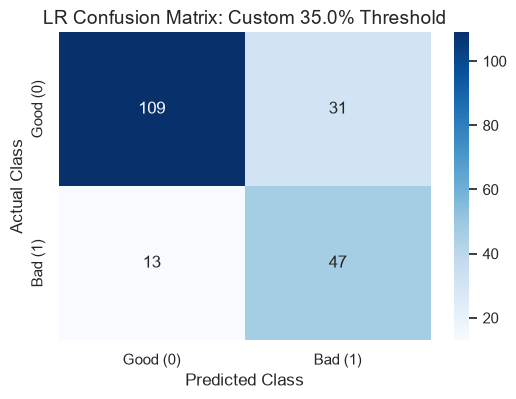

In [17]:
# Improving recall for LR
# 1. Import necessary tools
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Get the RAW probabilities from our trained model
# predict_proba returns [Probability of 0, Probability of 1]
probabilities = grid_search.predict_proba(X_test)

# 3. Isolate the probabilities for the 'Bad' class (Class 1 is in the second column)
prob_bad = probabilities[:, 1]

# 4. Use the stricter threshold selected with cross-validation on the training set
custom_threshold = best_threshold_lr

# 5. Create new predictions
# If probability is >= threshold, mark as 1 (Bad). Otherwise, mark as 0 (Good).
y_pred_custom = (prob_bad >= custom_threshold).astype(int)

# 6. Calculate the four core metrics using our new custom predictions
accuracy = accuracy_score(y_test, y_pred_custom)
precision = precision_score(y_test, y_pred_custom)
recall = recall_score(y_test, y_pred_custom)
f1 = f1_score(y_test, y_pred_custom)

# 7. Print the clean report
print(f"Logistic Regression Performance (Threshold: {custom_threshold*100}% | Target: Bad):\n")
print(f"Accuracy:  {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall:    {recall:.2f}")
print(f"F1-score:  {f1:.2f}\n")

# 8. Plot the new Confusion Matrix
cm = confusion_matrix(y_test, y_pred_custom)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Good (0)', 'Bad (1)'],
            yticklabels=['Good (0)', 'Bad (1)'])
plt.title(f'LR Confusion Matrix: Custom {custom_threshold*100}% Threshold', fontsize=14)
plt.ylabel('Actual Class', fontsize=12)
plt.xlabel('Predicted Class', fontsize=12)
plt.show()

---
## **Model Building: Linear Support Vector Machine (LinearSVM)**
---




In [18]:
# TUNING C FOR SVM
from sklearn.svm import LinearSVC

svm_model = LinearSVC(random_state=42, max_iter=10000)

svm_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor), # ohe, scaling
    ('classifier', svm_model)
])

param_grid_svm = {
    'classifier__C': [0.001, 0.01, 0.1, 1, 10, 100]
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search_svm = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid_svm,
    cv=cv_strategy,
    scoring='f1',
)

grid_search_svm.fit(X_train, y_train)

best_c_svm = grid_search_svm.best_params_['classifier__C']
print(f"Best value of C found for SVM: {best_c_svm}")
print(f"Best F1 score in cross-validation: {grid_search_svm.best_score_:.4f}\n")


Best value of C found for SVM: 1
Best F1 score in cross-validation: 0.5036



Linear SVC in test (C=1 | Target: Bad):

Accuracy:  0.78
Precision: 0.64
Recall:    0.57
F1-score:  0.60



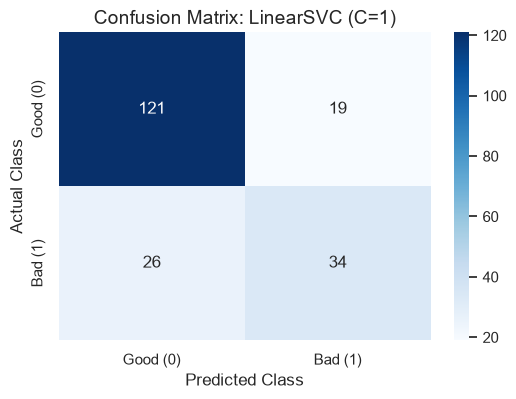

In [19]:
#evaluation
y_pred_svm = grid_search_svm.predict(X_test)

accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(y_test, y_pred_svm)
recall_svm = recall_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm)

print(f"Linear SVC in test (C={best_c_svm} | Target: Bad):\n")
print(f"Accuracy:  {accuracy_svm:.2f}")
print(f"Precision: {precision_svm:.2f}")
print(f"Recall:    {recall_svm:.2f}")
print(f"F1-score:  {f1_svm:.2f}\n")

cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Good (0)', 'Bad (1)'],
            yticklabels=['Good (0)', 'Bad (1)'])
plt.title(f'Confusion Matrix: LinearSVC (C={best_c_svm})', fontsize=14)
plt.ylabel('Actual Class', fontsize=12)
plt.xlabel('Predicted Class', fontsize=12)
plt.show()

In [20]:
# Choosing the SVM threshold with cross-validation (training set only)
# Same idea as with Logistic Regression, but using the decision scores (distance to the boundary)

# 1. Out-of-fold decision scores for the training set
best_svm = grid_search_svm.best_estimator_
oof_scores_svm = cross_val_predict(best_svm, X_train, y_train, cv=cv_strategy, method='decision_function')

# 2. Same business rule: at most 3 points of accuracy lost compared to the default threshold (0.0)
baseline_accuracy_svm = accuracy_score(y_train, (oof_scores_svm >= 0.0).astype(int))

# 3. Evaluate the candidate thresholds
candidate_thresholds_svm = np.round(np.arange(-0.50, 0.01, 0.05), 2) + 0.0  # + 0.0 avoids printing -0.0
threshold_results_svm = []
for t in candidate_thresholds_svm:
    y_oof = (oof_scores_svm >= t).astype(int)
    threshold_results_svm.append({
        'Threshold': t,
        'Accuracy':  accuracy_score(y_train, y_oof),
        'Recall':    recall_score(y_train, y_oof),
        'F1-score':  f1_score(y_train, y_oof)
    })
threshold_table_svm = pd.DataFrame(threshold_results_svm).round(3)

# 4. Highest recall among the thresholds that respect the rule
valid_svm = threshold_table_svm[threshold_table_svm['Accuracy'] >= baseline_accuracy_svm - max_accuracy_drop]
best_threshold_svm = float(valid_svm.sort_values('Recall', ascending=False).iloc[0]['Threshold'])

print(f"Out-of-fold accuracy with the default threshold (0.0): {baseline_accuracy_svm:.3f}")
print(f"Minimum accepted accuracy: {baseline_accuracy_svm - max_accuracy_drop:.3f}")
print(f"Threshold selected with cross-validation: {best_threshold_svm}")
print()
display(threshold_table_svm)


Out-of-fold accuracy with the default threshold (0.0): 0.738
Minimum accepted accuracy: 0.708
Threshold selected with cross-validation: -0.25



,Threshold,Accuracy,Recall,F1-score
0,-0.50,0.649,0.783,0.572
1,-0.45,0.661,0.750,0.571
2,-0.40,0.671,0.704,0.562
3,-0.35,0.688,0.696,0.572
4,-0.30,0.705,0.667,0.576
5,-0.25,0.712,0.638,0.571
6,-0.20,0.722,0.600,0.565
7,-0.15,0.724,0.554,0.546
8,-0.10,0.728,0.521,0.534
9,-0.05,0.739,0.488,0.528


LinearSVC Performance with Adjusted Threshold (-0.25):

Accuracy:  0.77
Precision: 0.59
Recall:    0.80
F1-score:  0.68



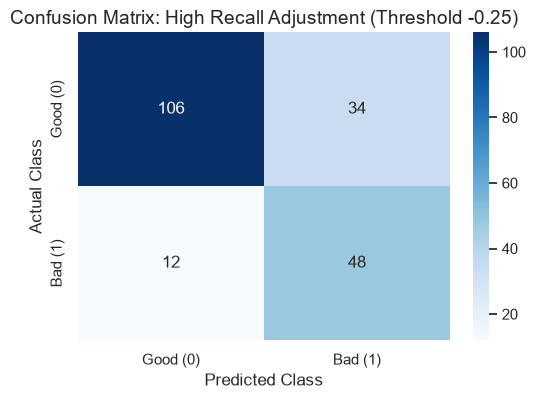

In [21]:
# Improving recall for SVM
# 1. Get the decision scores (distance to the boundary) for the Test set.
# We use the grid_search_svm that already contains the best trained model.
y_scores_svm = grid_search_svm.decision_function(X_test)

# 2. Use the threshold selected with cross-validation (the default value is 0.0)
# By lowering the threshold, we require less "evidence" to classify a case as "Bad" (1).
new_threshold = best_threshold_svm

# 3. Generate new predictions: If the score is >= the new threshold, it's class 1 (Bad).
y_pred_high_recall = (y_scores_svm >= new_threshold).astype(int)

# 4. Calculate the new metrics
acc_adj = accuracy_score(y_test, y_pred_high_recall)
prec_adj = precision_score(y_test, y_pred_high_recall)
rec_adj = recall_score(y_test, y_pred_high_recall)
f1_adj = f1_score(y_test, y_pred_high_recall)

# 5. Print the comparative results
print(f"LinearSVC Performance with Adjusted Threshold ({new_threshold}):\n")
print(f"Accuracy:  {acc_adj:.2f}")
print(f"Precision: {prec_adj:.2f}")
print(f"Recall:    {rec_adj:.2f}")
print(f"F1-score:  {f1_adj:.2f}\n")

# 6. New Confusion Matrix
cm_adj = confusion_matrix(y_test, y_pred_high_recall)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_adj, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Good (0)', 'Bad (1)'],
            yticklabels=['Good (0)', 'Bad (1)'])
plt.title(f'Confusion Matrix: High Recall Adjustment (Threshold {new_threshold})', fontsize=14)
plt.ylabel('Actual Class', fontsize=12)
plt.xlabel('Predicted Class', fontsize=12)
plt.show()

---
## **Model Building: k-Nearest Neighbors (kNN)**
---
Tune the number of neighbors and evaluate performance.


In [22]:

# Build kNN pipeline

knn_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier())
])


In [23]:
# Tune n_neighbors

param_grid_knn = {
    'classifier__n_neighbors': [3, 5, 7, 9, 11, 15, 21]
}

# Set up the Grid Search using the F1 score, just like we did for Logistic Regression
grid_search_knn = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid_knn,
    cv=cv_strategy, # Using the StratifiedKFold I defined earlier
    scoring='f1'
)

# Start the search
grid_search_knn.fit(X_train, y_train)

# Print the winning 'k'
best_k = grid_search_knn.best_params_['classifier__n_neighbors']
print(f"Grid Search complete! Best number of neighbors found: {best_k}\n")

Grid Search complete! Best number of neighbors found: 5



kNN Performance (k=5 | Default 50% Threshold | Target: Bad):

Accuracy:  0.72
Precision: 0.57
Recall:    0.35
F1-score:  0.43



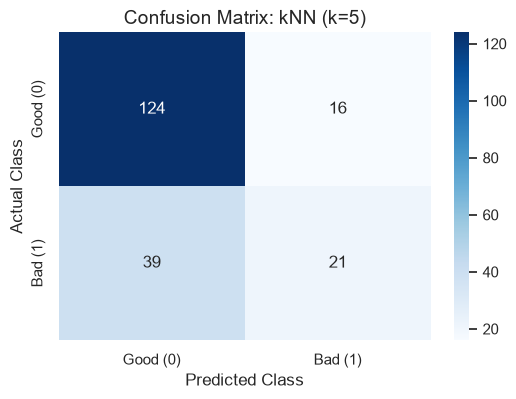

In [24]:
# Evaluate on test set
# The model takes the final exam using the unseen rows
y_pred_knn = grid_search_knn.predict(X_test)

# Calculate the four core metrics for the 'Bad' class (Target = 1)
accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn)
recall_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)

# Print the clean report
print(f"kNN Performance (k={best_k} | Default 50% Threshold | Target: Bad):\n")
print(f"Accuracy:  {accuracy_knn:.2f}")
print(f"Precision: {precision_knn:.2f}")
print(f"Recall:    {recall_knn:.2f}")
print(f"F1-score:  {f1_knn:.2f}\n")

# Plot the Confusion Matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(6, 4))

sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Good (0)', 'Bad (1)'],
            yticklabels=['Good (0)', 'Bad (1)'])
plt.title(f'Confusion Matrix: kNN (k={best_k})', fontsize=14)
plt.ylabel('Actual Class', fontsize=12)
plt.xlabel('Predicted Class', fontsize=12)
plt.show()

---
## **Model Performance Comparison**
---
- Compare Accuracy, Precision, Recall, and F1-score
- Interpret confusion matrices
- Which model performs best and why?


In [25]:

# 1. Create a dictionary that holds all the scores for our three models.
model_comparison = {
    'Model': [f'Logistic Regression (threshold {custom_threshold})', f'Linear SVM (threshold {new_threshold})', f'kNN (k={best_k})'],
    'Accuracy':  [accuracy, acc_adj, accuracy_knn],
    'Precision': [precision, prec_adj, precision_knn],
    'Recall':    [recall, rec_adj, recall_knn],
    'F1-Score':  [f1, f1_adj, f1_knn]
}

# 2. Convert the dictionary into a pandas DataFrame (a table)
results_table = pd.DataFrame(model_comparison)

# 3. Optional: Round the numbers to 2 decimal
results_table = results_table.round(2)

# 4. Display the table
print("Final Model Comparison (Target Class: Bad)\n")
display(results_table)


Final Model Comparison (Target Class: Bad)



,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression (threshold 0.35),0.78,0.60,0.78,0.68
1,Linear SVM (threshold -0.25),0.77,0.59,0.80,0.68
2,kNN (k=5),0.72,0.57,0.35,0.43


---
## **Discussion Questions (answered in the report: `docs/report.pdf`)**
---
1. Why can Logistic Regression and Linear SVM give different results even though both are linear?
2. Which models provide probability estimates? Why might this matter in credit risk?
3. What happens when C is very large or very small?
4. How does increasing k affect bias and variance in kNN?
5. Which model would you recommend and why?


---
## **Submission Checklist**
---
- All code runs without errors
- No data leakage
- Clear plots and labels
- Thoughtful EDA
- Clear model comparison
